## Notebook 3: Classification

In [2]:
# Loading necessary libraries for data manipulation, visualization, and machine learning tasks.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    roc_curve, 
    auc, 
    precision_recall_curve, 
    accuracy_score, 
    f1_score
)

### Step 2: Load data from prior notebooks

In [4]:
print("Loading processed feature matrix and label targets...")
try:
    X = pd.read_csv("data/normalized_mightee.csv")
    y_raw = pd.read_csv("data/y.csv").squeeze("columns") # ensure series layout
    print(f"Data successfully loaded. Feature Matrix Shape: {X.shape}, Labels Shape: {y_raw.shape}")
except FileNotFoundError:
    print("Error: Ensure data files exist in the paths specified at the end of Notebook 1.")

Loading processed feature matrix and label targets...
Data successfully loaded. Feature Matrix Shape: (4121, 38), Labels Shape: (4121,)


### Step 3: Binary Label Encoding

In [5]:
# Mapping text categories to numerical indicators: AGN -> 1, SFG -> 0
label_mapping = {"SFG": 0, "AGN": 1}
y = y_raw.map(label_mapping)

print("\nTarget Class Distributions:")
print(y_raw.value_counts())
print("\nNumerical Target Mapping Value Counts:")
print(y.value_counts())


Target Class Distributions:
target
SFG    2622
AGN    1499
Name: count, dtype: int64

Numerical Target Mapping Value Counts:
target
0    2622
1    1499
Name: count, dtype: int64


### Step 4: Stratified Train-Test Splitting

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing validation set shape: {X_test.shape}")


Training set shape: (3090, 38)
Testing validation set shape: (1031, 38)


### Step 5: Machine Learning ( Logistic Regression Model)

In [7]:
baseline_model = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)
print("\n--- Baseline Model Validation Performance ---")
print(classification_report(y_test, y_pred_baseline, target_names=["SFG", "AGN"]))


--- Baseline Model Validation Performance ---
              precision    recall  f1-score   support

         SFG       0.89      0.91      0.90       656
         AGN       0.84      0.81      0.83       375

    accuracy                           0.88      1031
   macro avg       0.87      0.86      0.87      1031
weighted avg       0.88      0.88      0.88      1031



### Tutorial ended here. The next steps would involve hyperparameter tuning, model evaluation, and interpretation,


Executing Hyperparameter Sweep...


/opt/homebrew/lib/python3.10/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/homebrew/lib/python3.10/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/homebrew/lib/python3.10/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/homebrew/lib/python3.10/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/homebrew/lib/python3.10/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/homebrew/lib/python3.10/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number 

Optimal Hyperparameter Weights Discovered: {'C': 1, 'penalty': 'l1', 'tol': 0.0001}

--- Optimized Model Validation Performance ---
              precision    recall  f1-score   support

         SFG       0.91      0.91      0.91       656
         AGN       0.84      0.85      0.85       375

    accuracy                           0.89      1031
   macro avg       0.88      0.88      0.88      1031
weighted avg       0.89      0.89      0.89      1031



/opt/homebrew/lib/python3.10/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


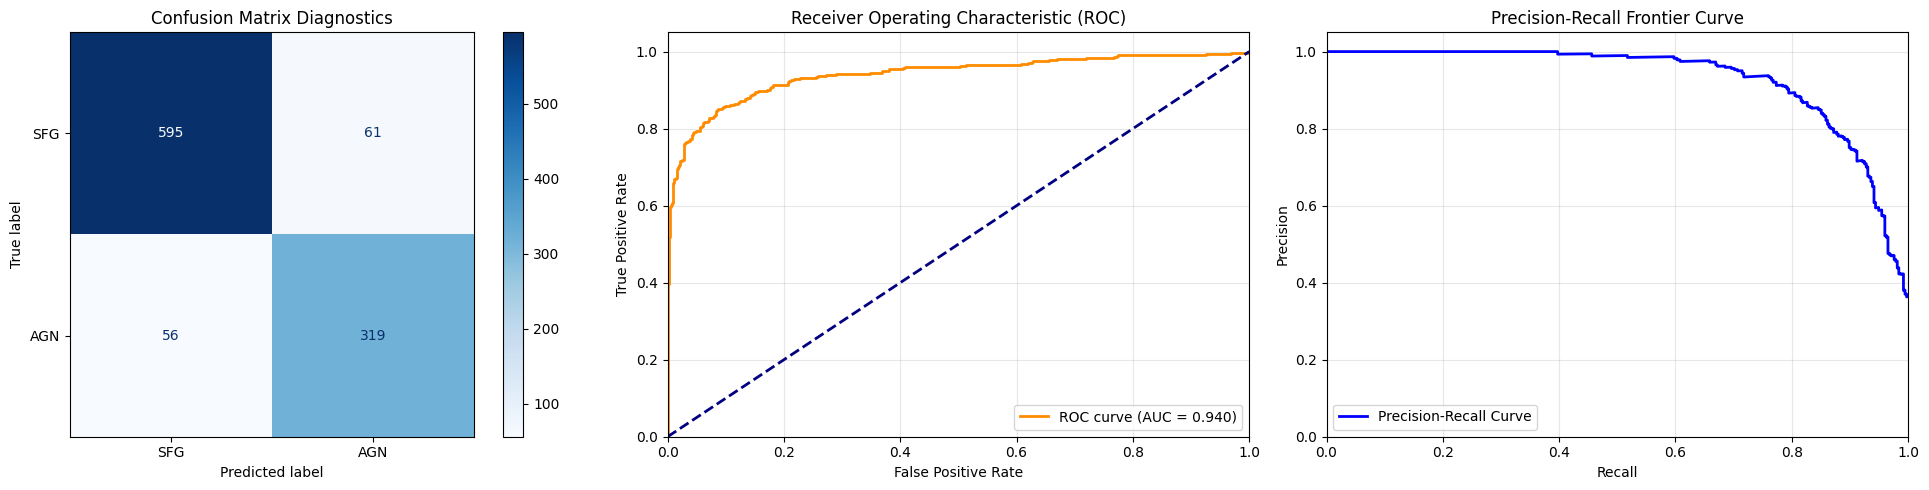

In [8]:
# ------------------------------------------
# Step 6: Hyperparameter Optimization via GridSearchCV
# ------------------------------------------
# Constructing grid to tune regularization type and regularizing magnitude (C)
param_grid = {
    'penalty': ['l1', 'l2'],
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'tol': [1e-4, 1e-3]
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced'),
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='f1_macro',
    n_jobs=-1
)

print("\nExecuting Hyperparameter Sweep...")
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(f"Optimal Hyperparameter Weights Discovered: {grid_search.best_params_}")

# Evaluate the optimized configurations
y_pred_opt = best_model.predict(X_test)
y_prob_opt = best_model.predict_proba(X_test)[:, 1]

print("\n--- Optimized Model Validation Performance ---")
print(classification_report(y_test, y_pred_opt, target_names=["SFG", "AGN"]))

# ------------------------------------------
# Step 7: Complete Performance Diagnostics and Visualizations
# ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Plot A: Confusion Matrix Diagram
cm = confusion_matrix(y_test, y_pred_opt)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["SFG", "AGN"])
cm_display.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Confusion Matrix Diagnostics')

# Plot B: Receiver Operating Characteristic (ROC) Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_opt)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)

# Plot C: Precision-Recall Curve (Crucial for astronomy surveys)
precision, recall, _ = precision_recall_curve(y_test, y_prob_opt)
axes[2].plot(recall, precision, color='blue', lw=2, label='Precision-Recall Curve')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall Frontier Curve')
axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].legend(loc="lower left")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()




Top 10 Most Predictive Astronomical Features for Binary Classification:
     Feature_Name  Coefficient_Weight  Absolute_Weight
              qir          -32.601800        32.601800
SPLASH_1_FLUX_ERR           21.923545        21.923545
             fAGN            5.551022         5.551022
          LIR_WHz            4.923290         4.923290
              fSF           -3.790118         3.790118
      F_SPIRE_250            2.450541         2.450541
             FLAG            1.555472         1.555472
  n_eff_SPIRE_350            1.429456         1.429456
    Separation_1c           -1.218958         1.218958
      PEAKFLUXERR            0.672566         0.672566


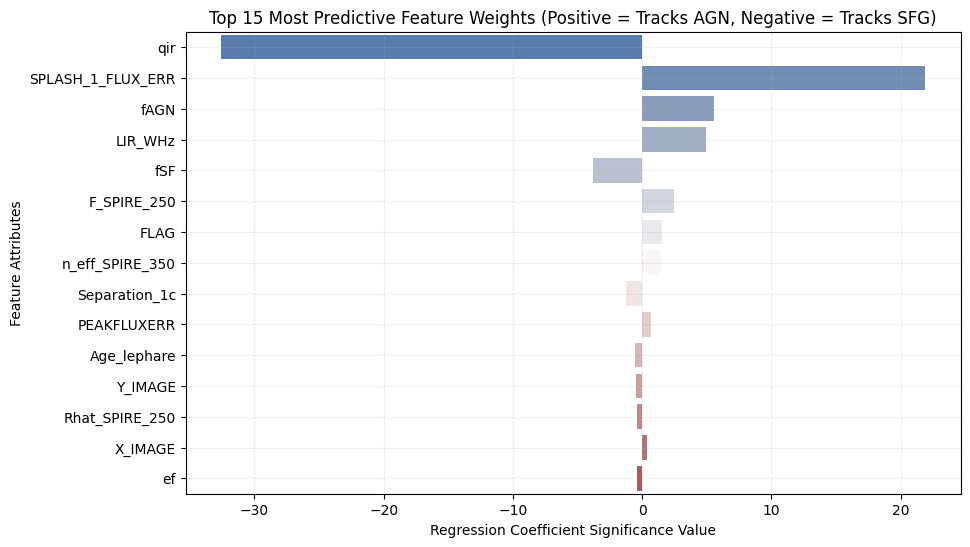

In [9]:
# ------------------------------------------
# Step 8: Astronomical Feature Importance Engineering
# ------------------------------------------
# Logistic regression weights display physical correlation to galaxy properties
feature_coefficients = best_model.coef_[0]
importance_df = pd.DataFrame({
    'Feature_Name': X.columns,
    'Coefficient_Weight': feature_coefficients,
    'Absolute_Weight': np.abs(feature_coefficients)
}).sort_values(by='Absolute_Weight', ascending=False)

print("\nTop 10 Most Predictive Astronomical Features for Binary Classification:")
print(importance_df.head(10).to_string(index=False))

# Plot feature weights top influences
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Coefficient_Weight', 
    y='Feature_Name', 
    data=importance_df.head(15), 
    palette='vlag',
    hue='Feature_Name',
    legend=False
)
plt.title('Top 15 Most Predictive Feature Weights (Positive = Tracks AGN, Negative = Tracks SFG)')
plt.xlabel('Regression Coefficient Significance Value')
plt.ylabel('Feature Attributes')
plt.grid(True, alpha=0.2)
plt.show()